# Week 3: Statistical Analysis and Hypothesis Testing in Python

## Project Title

**Statistical Analysis of Study Time and Academic Performance**

## 1. Introduction

Statistical analysis helps researchers identify patterns in data and evaluate whether observed relationships are likely to reflect a genuine population-level association. In education, understanding the relationship between students' study habits and academic performance can help inform academic support strategies.

This project analyzes the UCI Student Performance dataset using Python. The study focuses on the relationship between students' reported weekly study time and their final mathematics grades. Statistical methods are used to examine the strength of the association and compare academic performance between groups with different reported study times.

## 2. Research Question

Is there a statistically significant relationship between students' reported study time and their final mathematics grades?

## 3. Research Hypotheses

**Null hypothesis (H₀):** There is no monotonic association between reported study time and final mathematics grades in the population.

**Alternative hypothesis (H₁):** There is a monotonic association between reported study time and final mathematics grades in the population.

## 4. Significance Level

The significance level is set to α = 0.05. Statistical results will be evaluated using p-values, confidence intervals and effect sizes where appropriate.

## 5. Scope

The analysis uses observational student data. The results can identify statistical associations but cannot establish that study time alone causes differences in academic performance.



In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Create the output folder if it does not exist
os.makedirs("visualizations", exist_ok=True)

# Set chart style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv("data/student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df[["studytime", "G3"]].describe())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardi

,studytime,G3
count,395.000000,395.000000
mean,2.035443,10.415190
std,0.839240,4.581443
min,1.000000,0.000000
25%,1.000000,8.000000
50%,2.000000,11.000000
75%,2.000000,14.000000
max,4.000000,20.000000


In [3]:
# Keep only the columns needed for this study
analysis_df = df[["studytime", "G3"]].copy()

# Remove missing values and duplicate records
analysis_df = analysis_df.dropna()
analysis_df = analysis_df.drop_duplicates()

# Keep valid study-time categories and grades
analysis_df = analysis_df[
    analysis_df["studytime"].isin([1, 2, 3, 4])
    & analysis_df["G3"].between(0, 20)
]

analysis_df["studytime"] = analysis_df["studytime"].astype(int)
analysis_df["G3"] = analysis_df["G3"].astype(int)

print("Data cleaning completed.")
print("Rows available for analysis:", len(analysis_df))
print("\nStudy-time group counts:")
print(analysis_df["studytime"].value_counts().sort_index())

display(analysis_df.head())

Data cleaning completed.
Rows available for analysis: 59

Study-time group counts:
studytime
1    15
2    17
3    14
4    13
Name: count, dtype: int64


,studytime,G3
0,2,6
2,2,10
3,3,15
5,2,15
6,2,11


In [4]:
analysis_df = df[["studytime", "G3"]].copy()

analysis_df = analysis_df.dropna()
analysis_df = analysis_df[
    analysis_df["studytime"].isin([1, 2, 3, 4])
    & analysis_df["G3"].between(0, 20)
].copy()

analysis_df["studytime"] = analysis_df["studytime"].astype(int)
analysis_df["G3"] = analysis_df["G3"].astype(int)

print("Data preparation completed.")
print("Number of student records:", len(analysis_df))
print(analysis_df["studytime"].value_counts().sort_index())

Data preparation completed.
Number of student records: 395
studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64


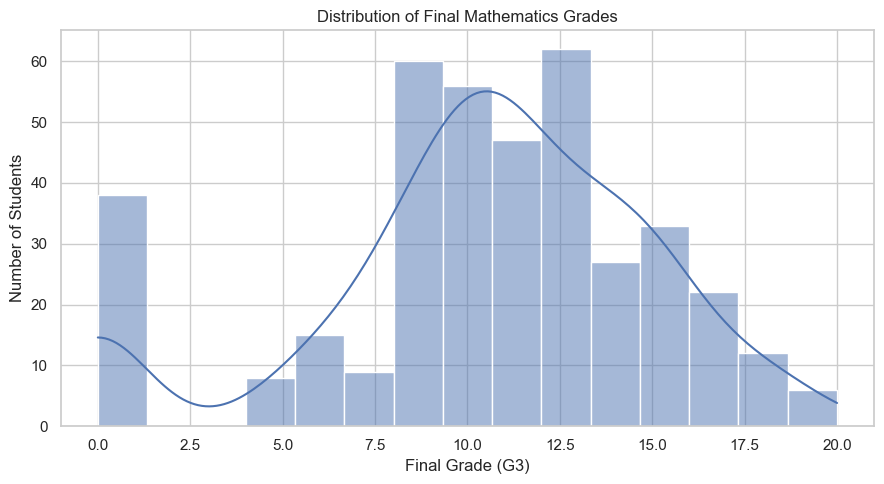

In [5]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=analysis_df,
    x="G3",
    bins=15,
    kde=True
)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig(
    "visualizations/01_grade_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

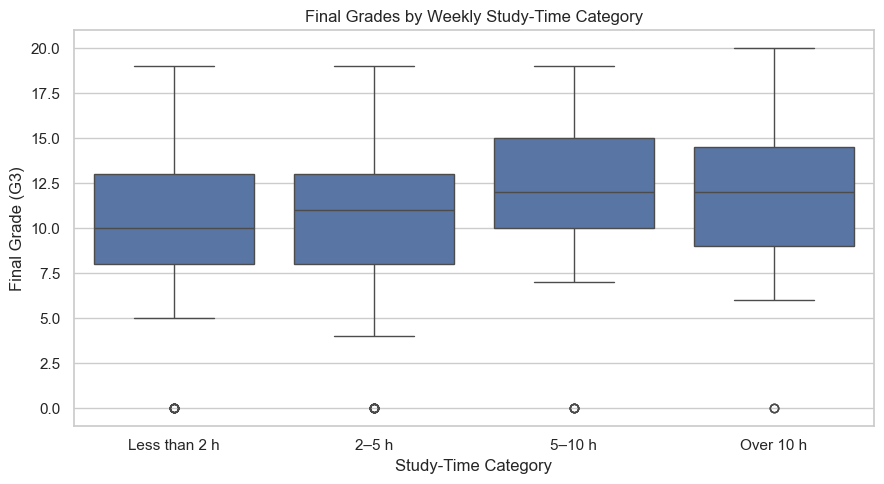

In [6]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=analysis_df,
    x="studytime",
    y="G3"
)

plt.title("Final Grades by Weekly Study-Time Category")
plt.xlabel("Study-Time Category")
plt.ylabel("Final Grade (G3)")
plt.xticks([0, 1, 2, 3], ["Less than 2 h", "2–5 h", "5–10 h", "Over 10 h"])
plt.tight_layout()

plt.savefig(
    "visualizations/02_grades_by_studytime.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

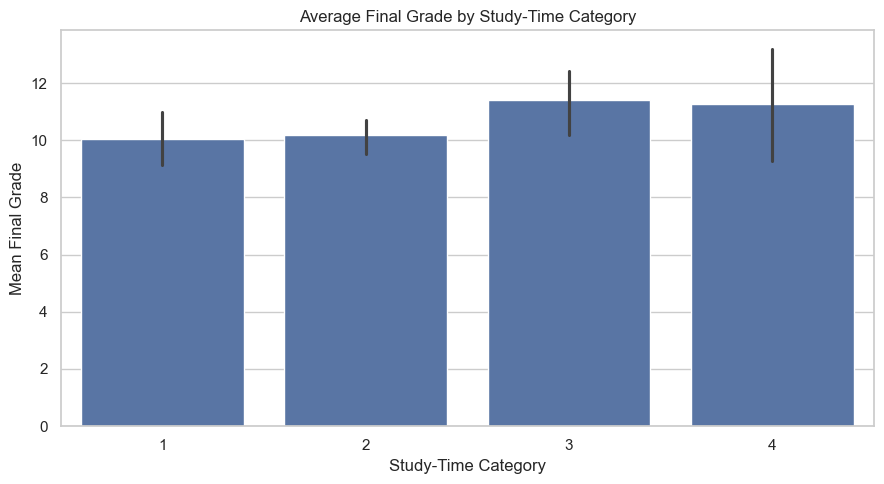

In [7]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=analysis_df,
    x="studytime",
    y="G3",
    errorbar=("ci", 95)
)

plt.title("Average Final Grade by Study-Time Category")
plt.xlabel("Study-Time Category")
plt.ylabel("Mean Final Grade")
plt.tight_layout()

plt.savefig(
    "visualizations/03_average_grade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

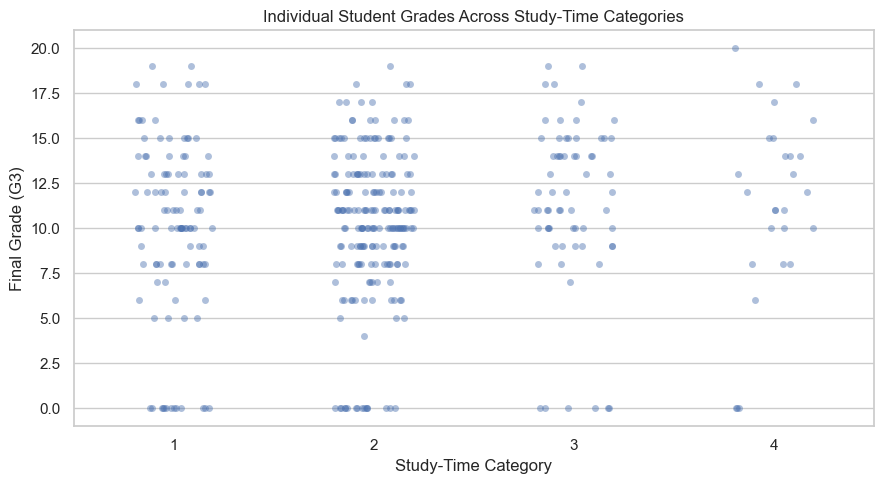

In [8]:
plt.figure(figsize=(9, 5))

sns.stripplot(
    data=analysis_df,
    x="studytime",
    y="G3",
    alpha=0.45,
    jitter=0.2
)

plt.title("Individual Student Grades Across Study-Time Categories")
plt.xlabel("Study-Time Category")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()

plt.savefig(
    "visualizations/04_studytime_grade_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Spearman rank correlation
rho, p_value = stats.spearmanr(
    analysis_df["studytime"],
    analysis_df["G3"]
)

print("SPEARMAN CORRELATION TEST")
print("-------------------------")
print(f"Spearman correlation (rho): {rho:.4f}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Interpretation: A statistically significant monotonic association was found.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Interpretation: The data do not provide sufficient evidence of a monotonic association.")

SPEARMAN CORRELATION TEST
-------------------------
Spearman correlation (rho): 0.1052
P-value: 0.036674
Decision: Reject the null hypothesis.
Interpretation: A statistically significant monotonic association was found.


In [10]:
low_study = analysis_df.loc[
    analysis_df["studytime"].isin([1, 2]), "G3"
]

high_study = analysis_df.loc[
    analysis_df["studytime"].isin([3, 4]), "G3"
]

print("LOWER STUDY-TIME GROUP")
print("Sample size:", len(low_study))
print("Mean grade:", round(low_study.mean(), 3))
print("Standard deviation:", round(low_study.std(ddof=1), 3))

print("\nHIGHER STUDY-TIME GROUP")
print("Sample size:", len(high_study))
print("Mean grade:", round(high_study.mean(), 3))
print("Standard deviation:", round(high_study.std(ddof=1), 3))

# Welch's t-test
t_stat, t_p_value = stats.ttest_ind(
    high_study,
    low_study,
    equal_var=False
)

# Difference in sample means: higher minus lower
mean_difference = high_study.mean() - low_study.mean()

# 95% confidence interval for the difference in population means
comparison = CompareMeans(
    DescrStatsW(high_study),
    DescrStatsW(low_study)
)

ci_low, ci_high = comparison.tconfint_diff(
    alpha=0.05,
    usevar="unequal"
)

print("\nWELCH'S T-TEST")
print("--------------")
print(f"Mean difference: {mean_difference:.3f}")
print(f"t-statistic: {t_stat:.4f}")
print(f"P-value: {t_p_value:.6f}")
print(f"95% confidence interval: ({ci_low:.3f}, {ci_high:.3f})")

LOWER STUDY-TIME GROUP
Sample size: 303
Mean grade: 10.129
Standard deviation: 4.48

HIGHER STUDY-TIME GROUP
Sample size: 92
Mean grade: 11.359
Standard deviation: 4.807

WELCH'S T-TEST
--------------
Mean difference: 1.230
t-statistic: 2.1831
P-value: 0.030669
95% confidence interval: (0.116, 2.344)


In [11]:
# Prepare four groups
groups = [
    analysis_df.loc[analysis_df["studytime"] == category, "G3"]
    for category in [1, 2, 3, 4]
]

# One-way ANOVA
f_stat, anova_p = stats.f_oneway(*groups)

print("ONE-WAY ANOVA")
print("-------------")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {anova_p:.6f}")

if anova_p < 0.05:
    print("Decision: Reject the null hypothesis.")
    print("At least one group mean differs from another.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence that the group means differ.")

ONE-WAY ANOVA
-------------
F-statistic: 1.7278
P-value: 0.160723
Decision: Fail to reject the null hypothesis.
There is insufficient evidence that the group means differ.


In [12]:
X = sm.add_constant(analysis_df["studytime"])
y = analysis_df["G3"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     3.797
Date:                Sun, 04 Oct 2026   Prob (F-statistic):             0.0521
Time:                        20:44:02   Log-Likelihood:                -1159.3
No. Observations:                 395   AIC:                             2323.
Df Residuals:                     393   BIC:                             2331.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.3283      0.603     15.463      0.0

In [13]:
results = pd.DataFrame({
    "Test": [
        "Spearman correlation",
        "Welch independent-samples t-test",
        "One-way ANOVA"
    ],
    "Statistic": [
        rho,
        t_stat,
        f_stat
    ],
    "P-value": [
        p_value,
        t_p_value,
        anova_p
    ]
})

results.to_csv(
    "statistical_test_results.csv",
    index=False
)

display(results)

print("Statistical results saved successfully!")

,Test,Statistic,P-value
0,Spearman correlation,0.105170,0.036674
1,Welch independent-samples t-test,2.183077,0.030669
2,One-way ANOVA,1.727835,0.160723


Statistical results saved successfully!


In [14]:

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
import os

# Create the Word document
doc = Document()

# Page margins
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Set default font
styles = doc.styles
styles["Normal"].font.name = "Arial"
styles["Normal"].font.size = Pt(10)

# Helper functions
def add_heading(text, level=1):
    doc.add_heading(text, level=level)

def add_paragraph(text):
    doc.add_paragraph(str(text))

def add_figure(path, caption):
    if os.path.exists(path):
        doc.add_picture(path, width=Inches(5.8))
        doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
        p = doc.add_paragraph(caption)
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    else:
        add_paragraph(f"Figure not inserted: {path} was not found.")

# --------------------------------------------------
# TITLE PAGE
# --------------------------------------------------
title = doc.add_heading(
    "STATISTICAL ANALYSIS AND HYPOTHESIS TESTING",
    0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

p = doc.add_paragraph(
    "Project: Statistical Analysis of Study Time and Academic Performance"
)
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

p = doc.add_paragraph(
    "Week 3 Python Data Science Task\n"
    "Submitted by: [Enter Your Name]\n"
    "Tools: Python, Pandas, SciPy, Statsmodels, Matplotlib and Seaborn"
)
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_page_break()

# --------------------------------------------------
# ABSTRACT
# --------------------------------------------------
add_heading("Abstract")

add_paragraph(
    "This project investigates the relationship between students' "
    "reported weekly study time and final mathematics grades using "
    "the UCI Student Performance dataset. Python is used for data "
    "preparation, visualization and statistical hypothesis testing. "
    "Spearman rank correlation is the primary analysis, while Welch's "
    "independent-samples t-test, one-way ANOVA and linear regression "
    "provide supplementary perspectives. The findings are interpreted "
    "using a 5% significance level. Because the dataset is observational, "
    "the results describe associations rather than establishing causation."
)

# --------------------------------------------------
# INTRODUCTION
# --------------------------------------------------
add_heading("1. Introduction")

add_paragraph(
    "Statistical analysis enables researchers to investigate patterns "
    "in data and evaluate evidence for relationships between variables. "
    "In education, reported study habits may be associated with academic "
    "performance. This project examines that relationship using student "
    "data and statistical methods implemented in Python."
)

add_heading("2. Objectives")

objectives = [
    "Inspect and prepare a public student performance dataset.",
    "Summarize final mathematics grades and study-time categories.",
    "Visualize the distribution of grades and group differences.",
    "Test the association between study time and final grades.",
    "Compare group means and calculate a confidence interval.",
    "Interpret the statistical findings and their limitations."
]

for objective in objectives:
    doc.add_paragraph(objective, style="List Bullet")

# --------------------------------------------------
# DATASET AND HYPOTHESES
# --------------------------------------------------
add_heading("3. Dataset Description")

add_paragraph(
    f"The analysis uses the UCI Student Performance mathematics dataset. "
    f"The original dataset contains {len(df)} student records and "
    f"{len(df.columns)} columns. The prepared analysis contains "
    f"{len(analysis_df)} valid records for the selected variables."
)

add_paragraph(
    "The studytime variable represents reported weekly study time "
    "in four ordered categories. G3 represents the final mathematics "
    "grade on a scale from 0 to 20."
)

add_heading("4. Research Question and Hypotheses")

add_paragraph(
    "Research question: Is there a statistically significant "
    "monotonic association between reported study time and final "
    "mathematics grades?"
)

add_paragraph(
    "Null hypothesis (H0): There is no monotonic association between "
    "study time and final mathematics grades in the population."
)

add_paragraph(
    "Alternative hypothesis (H1): There is a monotonic association "
    "between study time and final mathematics grades in the population."
)

add_paragraph(
    "The significance level is alpha = 0.05. A p-value below 0.05 "
    "is treated as evidence against the corresponding null hypothesis."
)

# --------------------------------------------------
# METHODOLOGY
# --------------------------------------------------
add_heading("5. Methodology")

add_paragraph(
    "The dataset was loaded using Pandas and the relevant variables "
    "were checked for missing values and valid ranges. Exploratory "
    "visualizations were created using Matplotlib and Seaborn. "
    "Spearman correlation assessed the monotonic association between "
    "the ordinal study-time categories and final grades. Welch's "
    "t-test compared mean grades between categories 1-2 and categories "
    "3-4. One-way ANOVA compared means across all four categories. "
    "Ordinary least squares regression summarized the coded linear trend."
)

# --------------------------------------------------
# DESCRIPTIVE STATISTICS
# --------------------------------------------------
add_heading("6. Descriptive Statistics")

desc = analysis_df[["studytime", "G3"]].describe()

table = doc.add_table(rows=1, cols=3)
table.style = "Light Shading Accent 1"

hdr = table.rows[0].cells
hdr[0].text = "Statistic"
hdr[1].text = "Study Time"
hdr[2].text = "Final Grade (G3)"

for stat_name, row in desc.iterrows():
    cells = table.add_row().cells
    cells[0].text = str(stat_name)
    cells[1].text = f"{row['studytime']:.3f}"
    cells[2].text = f"{row['G3']:.3f}"

# --------------------------------------------------
# VISUALIZATIONS
# --------------------------------------------------
add_heading("7. Visual Analysis")

figures = [
    (
        "visualizations/01_grade_distribution.png",
        "Figure 1: Distribution of final mathematics grades."
    ),
    (
        "visualizations/02_grades_by_studytime.png",
        "Figure 2: Final grades by study-time category."
    ),
    (
        "visualizations/03_average_grade.png",
        "Figure 3: Average final grade by study-time category."
    ),
    (
        "visualizations/04_studytime_grade_scatter.png",
        "Figure 4: Individual grades across study-time categories."
    )
]

for path, caption in figures:
    add_figure(path, caption)

# --------------------------------------------------
# STATISTICAL RESULTS
# --------------------------------------------------
add_heading("8. Spearman Rank Correlation")

add_paragraph(f"Spearman correlation coefficient: {rho:.4f}")
add_paragraph(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    add_paragraph(
        "Decision: Reject the null hypothesis for the Spearman test. "
        "The result provides evidence of a monotonic association."
    )
else:
    add_paragraph(
        "Decision: Fail to reject the null hypothesis for the Spearman "
        "test. The result does not provide sufficient evidence of a "
        "monotonic association."
    )

add_heading("9. Welch's Independent-Samples t-Test")

add_paragraph(f"Lower study-time group size: {len(low_study)}")
add_paragraph(f"Higher study-time group size: {len(high_study)}")
add_paragraph(f"Lower group mean: {low_study.mean():.3f}")
add_paragraph(f"Higher group mean: {high_study.mean():.3f}")
add_paragraph(f"Mean difference (higher minus lower): {mean_difference:.3f}")
add_paragraph(f"t-statistic: {t_stat:.4f}")
add_paragraph(f"P-value: {t_p_value:.6f}")
add_paragraph(
    f"95% confidence interval for the mean difference: "
    f"({ci_low:.3f}, {ci_high:.3f})"
)

if t_p_value < 0.05:
    add_paragraph(
        "Decision: Reject the null hypothesis of equal population means "
        "for this two-group comparison."
    )
else:
    add_paragraph(
        "Decision: Fail to reject the null hypothesis of equal population "
        "means for this two-group comparison."
    )

add_heading("10. One-Way ANOVA")

add_paragraph(f"F-statistic: {f_stat:.4f}")
add_paragraph(f"P-value: {anova_p:.6f}")

if anova_p < 0.05:
    add_paragraph(
        "Decision: Reject the null hypothesis that all four population "
        "means are equal. At least one population mean differs."
    )
else:
    add_paragraph(
        "Decision: Fail to reject the null hypothesis that all four "
        "population means are equal."
    )

add_heading("11. Regression Analysis")

add_paragraph(
    f"Estimated slope for study-time category: "
    f"{model.params['studytime']:.4f}"
)

add_paragraph(
    f"95% confidence interval for the slope: "
    f"({model.conf_int().loc['studytime', 0]:.4f}, "
    f"{model.conf_int().loc['studytime', 1]:.4f})"
)

add_paragraph(
    f"Regression p-value for the slope: "
    f"{model.pvalues['studytime']:.6f}"
)

add_paragraph(
    "The regression slope describes the estimated change in grade "
    "associated with a one-category increase in the coded study-time "
    "variable. It does not represent the effect of one additional hour."
)

# --------------------------------------------------
# LIMITATIONS AND CONCLUSION
# --------------------------------------------------
add_heading("12. Limitations")

add_paragraph(
    "The study uses observational data and cannot establish causation. "
    "Study time is reported in broad categories rather than exact hours. "
    "Other factors, including prior achievement, attendance, motivation "
    "and family circumstances, may influence grades. Statistical "
    "assumptions should be checked before drawing firm conclusions. "
    "The findings may not generalize to every student population."
)

add_heading("13. Conclusion")

add_paragraph(
    f"The Spearman test produced a correlation coefficient of "
    f"{rho:.4f} and a p-value of {p_value:.6f}. "
    + (
        "The primary test provides evidence of a statistically significant "
        "monotonic association at the 5% level. "
        if p_value < 0.05
        else "The primary test does not provide sufficient evidence of a "
             "monotonic association at the 5% level. "
    )
    + "The Welch t-test and ANOVA provide supplementary comparisons of "
      "academic performance across study-time groups. These results should "
      "be interpreted alongside confidence intervals, test assumptions "
      "and the limitations of observational data. The analysis does not "
      "establish that study time alone causes differences in grades."
)

# --------------------------------------------------
# REFERENCES
# --------------------------------------------------
add_heading("14. References")

references = [
    "Cortez, P., and Silva, A. M. G. (2008). Using Data Mining to "
    "Predict Secondary School Student Performance. FUBUTEC 2008.",
    "UCI Machine Learning Repository. Student Performance Dataset. "
    "https://archive.ics.uci.edu/dataset/320/student+performance",
    "SciPy Documentation: https://docs.scipy.org/doc/scipy/",
    "Statsmodels Documentation: https://www.statsmodels.org/",
    "Pandas Documentation: https://pandas.pydata.org/docs/"
]

for reference in references:
    doc.add_paragraph(reference, style="List Number")

# --------------------------------------------------
# SAVE DOCUMENT
# --------------------------------------------------
output_file = "Week3_Hypothesis_Testing_Report.docx"
doc.save(output_file)

print("Report created successfully!")
print("Saved at:", os.path.abspath(output_file))

Report created successfully!
Saved at: c:\Users\YASH  R AMBATKAR\OneDrive\Desktop\Week3_Hypothesis_Testing\Week3_Hypothesis_Testing_Report.docx
